# MineSight · Segmentación operativa de la flotación de hierro

**Universidad Peruana Cayetano Heredia · Machine Learning · Proyecto Final 2026-II**  
Modelo desarrollado en el Challenge 4 de Clustering y Segmentación.

[Notebook en Kaggle](https://www.kaggle.com/code/marcoanccoquispe/minesight-clustering-y-segmentaci-n-minera) · [Código en GitHub](https://github.com/Marco404-Dev/MineSight) · [Demo en Vercel](https://minesight-vert.vercel.app/) · [Writeup](https://github.com/Marco404-Dev/MineSight/blob/main/docs/MineSight_WriteUp.pdf)

## 1. Contexto

En flotación, la composición de la alimentación, los caudales de reactivos y las propiedades de la pulpa cambian simultáneamente. La ley de hierro y la sílice del concentrado permiten describir el producto final.

## 2. Problema y usuario objetivo

El usuario principal es el metalurgista de procesos o analista de planta que revisa datos de operación por turno. Cuando aparecen diferencias de calidad o caudal, debe buscar horas históricas con condiciones comparables entre varias series. El historial del estudio contiene 737 453 registros y carece de etiquetas de régimen. La pregunta del proyecto es **qué grupos de horas tienen condiciones operativas similares y cómo puede el usuario reconocerlos en un turno nuevo**.

En MineSight el usuario carga un CSV de turno, revisa su formato y obtiene las asignaciones y perfiles por grupo. Puede inspeccionar una hora con la entrada manual y exportar los resultados para contrastarlos con los registros de planta y laboratorio. La clasificación sirve para priorizar la revisión metalúrgica.

## 3. Objetivo general

Construir una referencia histórica de condiciones de flotación de hierro a escala horaria e integrar su consulta en una aplicación web.

## 4. Objetivos específicos

1. Preparar y estandarizar siete variables operativas.
2. Seleccionar el número de grupos y comparar K-Means con MiniBatch K-Means.
3. Evaluar la separación interna y la estabilidad frente a semillas de inicialización.
4. Perfilar los grupos, interpretar las diferencias observadas y exponer el alcance de la aplicación.


## 5. Descripción del dataset

**Nombre:** Quality Prediction in a Mining Process  
**Fuente:** [Ficha del dataset en Kaggle](https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process)  
**Autor:** Eduardo Magalhães Oliveira  
**Sector:** Minería — procesamiento de mineral de hierro  
**Licencia:** CC0 — Dominio público  
**Periodo:** Marzo a septiembre de 2017

### Características del conjunto de datos

El dataset contiene 737 453 registros y 24 columnas, correspondientes a mediciones industriales de una planta de flotación de mineral de hierro.

Las variables incluyen concentraciones de hierro y sílice, flujo de reactivos, pH, densidad de pulpa, flujo de pulpa y mediciones de las columnas de flotación.

### Variables seleccionadas

Se eligieron siete variables disponibles para comparar condiciones de entrada y operación por hora. Hierro y sílice describen la alimentación. Almidón y amina describen los caudales de reactivos. Caudal, pH y densidad describen el estado de la pulpa. Aire y niveles de columnas quedaron fuera del ajuste y pueden evaluarse en un estudio posterior.

| Variable | Descripción |
|---|---|
| % Iron Feed | Porcentaje de hierro en la alimentación |
| % Silica Feed | Porcentaje de sílice en la alimentación |
| Starch Flow | Flujo de almidón |
| Amina Flow | Flujo de amina |
| Ore Pulp Flow | Flujo de pulpa |
| Ore Pulp pH | Nivel de pH de la pulpa |
| Ore Pulp Density | Densidad de la pulpa |

**Unidad de análisis:** una hora de operación de la planta.

### Preparación de datos

Se realizaron las siguientes operaciones:

1. Carga y revisión del dataset.
2. Conversión de la columna temporal.
3. Identificación de valores faltantes y duplicados.
4. Eliminación de registros duplicados exactos.
5. Agregación de las mediciones por hora mediante la media aritmética.
6. Selección de siete variables operativas.
7. Estandarización con StandardScaler.

La auditoría registró 0 faltantes por columna y 1 171 duplicados exactos. Después de eliminarlos quedaron 736 282 filas. La media por cada marca horaria de `date` y la selección de entradas produjeron 4 097 observaciones. Se conservaron las escalas originales antes de ajustar StandardScaler. El hierro y la sílice del concentrado se unieron por hora después de asignar los grupos, para el análisis descriptivo.

### Limitaciones del dataset

- Los datos corresponden a un periodo histórico de 2017.
- El dataset representa las condiciones de una planta específica.
- Existen variables registradas con diferentes frecuencias de muestreo.
- La agregación horaria reduce la resolución temporal de los datos.
- No se dispone de información suficiente para calcular costos operativos o validar recomendaciones de optimización.


## 6. Modelamiento y evaluación

K-Means aprovecha que todas las entradas son numéricas. Usa distancias euclidianas en el espacio estandarizado y minimiza la suma de distancias cuadráticas al centroide dentro de cada grupo. StandardScaler aplica $z_j=(x_j-\mu_j)/\sigma_j$ para llevar las siete entradas a una escala comparable. El centroide se puede expresar en las variables originales para que el usuario compare perfiles y, usando el mismo escalador, asignar nuevas horas. La geometría del método favorece grupos compactos y el más cercano siempre recibe la observación, incluso si está lejos de todos.

| Experimento | Configuración | Regla de análisis |
|---|---|---|
| Barrido de K-Means | k de 2 a 8, `random_state=42`, `n_init=10` | Selección por mayor silhouette, con inercia como descripción del ajuste |
| K-Means final | k=7, `random_state=42`, `n_init=10` | Centroides para inferencia y perfilamiento |
| MiniBatch K-Means | k=7, `random_state=42`, `n_init=10`, `batch_size=256` | Mismas entradas, actualización por minilotes |
| Estabilidad | k=7, `n_init=10`, semillas 0, 10, 21, 42 y 100 | ARI contra semilla 0 usando las mismas 4 097 horas |

Silhouette mide cohesión y separación (mayor es mejor). Davies–Bouldin contrasta dispersión interna y distancia entre perfiles (menor es mejor). Calinski–Harabasz compara dispersión entre grupos y dentro de ellos (mayor es mejor). ARI mide concordancia corregida por azar entre particiones. El PCA de dos componentes se usa para visualizar y conserva 58,89 % de la varianza. La inferencia usa las siete entradas estandarizadas.

Para reproducir en Kaggle, adjunta el dataset enlazado y ejecuta las celdas en orden. El notebook lee el CSV bajo `/kaggle/input` con coma decimal y exporta tres PKL bajo `/kaggle/working/modelos`.

La verificación local usó scikit-learn 1.6.1, la versión requerida por los PKL del repositorio. Se recomienda esta versión para contrastar las salidas con los artefactos originales.


In [1]:

import pandas as pd
import os

# Encontrar automáticamente nuestro archivo CSV
archivos = []

for carpeta, _, nombres in os.walk('/kaggle/input'):
    for nombre in nombres:
        if nombre.endswith('.csv'):
            archivos.append(os.path.join(carpeta, nombre))

print("Archivos encontrados:", archivos)

# Cargar dataset
ruta = next(
    archivo for archivo in archivos
    if 'MiningProcess_Flotation_Plant_Database.csv' in archivo
)

df = pd.read_csv(ruta, decimal=',')

print("Total de filas:", df.shape[0])
print("Total de columnas:", df.shape[1])

display(df.head())


Archivos encontrados: ['/kaggle/input/datasets/edumagalhaes/quality-prediction-in-a-mining-process/MiningProcess_Flotation_Plant_Database.csv']
Total de filas: 737453
Total de columnas: 24


,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


In [2]:

# MINESIGHT - PASO 4: LIMPIEZA DE DATOS

# Crear una copia para trabajar
datos = df.copy()

# Convertir fecha
datos["date"] = pd.to_datetime(
    datos["date"], errors="coerce"
)

# Revisar valores faltantes
print("VALORES FALTANTES:")
print(datos.isnull().sum())

# Revisar filas duplicadas
print("\nFILAS DUPLICADAS:")
print(datos.duplicated().sum())

# Eliminar filas duplicadas
datos = datos.drop_duplicates().copy()

# Revisar tipos de datos
print("\nTIPOS DE DATOS:")
print(datos.dtypes)

# Mostrar dimensiones finales
print("\nDIMENSIONES DESPUES DE LIMPIEZA:")
print(datos.shape)

display(datos.head())


VALORES FALTANTES:
date                            0
% Iron Feed                     0
% Silica Feed                   0
Starch Flow                     0
Amina Flow                      0
Ore Pulp Flow                   0
Ore Pulp pH                     0
Ore Pulp Density                0
Flotation Column 01 Air Flow    0
Flotation Column 02 Air Flow    0
Flotation Column 03 Air Flow    0
Flotation Column 04 Air Flow    0
Flotation Column 05 Air Flow    0
Flotation Column 06 Air Flow    0
Flotation Column 07 Air Flow    0
Flotation Column 01 Level       0
Flotation Column 02 Level       0
Flotation Column 03 Level       0
Flotation Column 04 Level       0
Flotation Column 05 Level       0
Flotation Column 06 Level       0
Flotation Column 07 Level       0
% Iron Concentrate              0
% Silica Concentrate            0
dtype: int64

FILAS DUPLICADAS:
1171

TIPOS DE DATOS:
date                            datetime64[ns]
% Iron Feed                            float64
% Silica Feed    

,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


In [3]:

# MINESIGHT - PASO 5: PREPARACION

from sklearn.preprocessing import StandardScaler

# Seleccionar variables operativas
variables = [
    "% Iron Feed",
    "% Silica Feed",
    "Starch Flow",
    "Amina Flow",
    "Ore Pulp Flow",
    "Ore Pulp pH",
    "Ore Pulp Density"
]

# Agrupar mediciones por hora
datos_hora = datos.groupby("date")[variables].mean()

# Eliminar registros incompletos
datos_hora = datos_hora.dropna()

# Normalizar las variables
escalador = StandardScaler()
X = escalador.fit_transform(datos_hora)

print("Registros para entrenamiento:", X.shape[0])
print("Variables utilizadas:", X.shape[1])

display(datos_hora.head())


Registros para entrenamiento: 4097
Variables utilizadas: 7


,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density
date,,,,,,,
2017-03-10 01:00:00,55.2,16.98,3162.625026,578.786678,398.753368,10.113487,1.729558
2017-03-10 02:00:00,55.2,16.98,3133.256389,537.219661,399.871822,10.129742,1.667784
2017-03-10 03:00:00,55.2,16.98,3479.482944,591.906744,398.763806,10.048403,1.732711
2017-03-10 04:00:00,55.2,16.98,3228.036436,593.170106,399.866983,9.918614,1.731056
2017-03-10 05:00:00,55.2,16.98,3327.280739,619.710806,399.615089,9.746029,1.765879


,Clusters,Silhouette,Inercia
0,2,0.202678,22795.584933
1,3,0.215710,18582.408033
2,4,0.224989,16232.316144
3,5,0.221791,14376.377929
4,6,0.215199,13145.243846
5,7,0.226228,12226.121395
6,8,0.209994,11590.235245


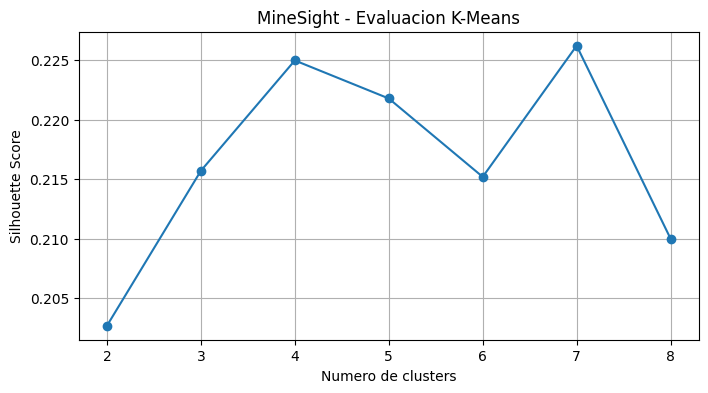

In [4]:

# MINESIGHT - PASO 6: ENTRENAMIENTO K-MEANS

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Comparar diferentes cantidades de clusters
resultados = []

for k in range(2, 9):
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X)

    silhouette = silhouette_score(X, etiquetas)

    resultados.append({
        "Clusters": k,
        "Silhouette": silhouette,
        "Inercia": modelo.inertia_
    })

resultados_df = pd.DataFrame(resultados)

display(resultados_df)

# Graficar resultados
plt.figure(figsize=(8, 4))
plt.plot(
    resultados_df["Clusters"],
    resultados_df["Silhouette"],
    marker="o"
)

plt.title("MineSight - Evaluacion K-Means")
plt.xlabel("Numero de clusters")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()


In [5]:

# MINESIGHT - PASO 7: ANALISIS DE CLUSTERS

from sklearn.cluster import KMeans

# Entrenar modelo con 7 clusters
modelo_kmeans = KMeans(
    n_clusters=7,
    random_state=42,
    n_init=10
)

# Asignar grupos
clusters = modelo_kmeans.fit_predict(X)

# Crear tabla de resultados
resultado = datos_hora.copy()
resultado["Cluster"] = clusters

# Cantidad de registros por cluster
print("DISTRIBUCION DE CLUSTERS:")
display(
    resultado["Cluster"]
    .value_counts()
    .sort_index()
    .to_frame("Cantidad")
)

# Perfil promedio de cada cluster
print("PERFIL DE LOS CLUSTERS:")
perfil = resultado.groupby("Cluster").mean()

display(perfil.round(2))


DISTRIBUCION DE CLUSTERS:


,Cantidad
Cluster,
0,717
1,581
2,471
3,795
4,247
5,382
6,904


PERFIL DE LOS CLUSTERS:


,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density
Cluster,,,,,,,
0,56.97,12.71,3775.59,531.62,401.02,10.06,1.71
1,49.75,24.05,3341.13,532.78,401.41,9.89,1.70
2,55.77,15.04,1662.71,354.11,397.27,9.56,1.56
3,63.63,6.41,3088.70,475.21,400.61,9.87,1.66
4,57.50,11.92,2894.73,471.30,382.00,9.24,1.69
5,50.90,22.13,3081.87,469.01,381.00,9.85,1.69
6,55.74,14.78,2184.43,518.94,401.13,9.58,1.72


In [6]:

# MINESIGHT - PASO 8: COMPARACION DE MODELOS

from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Modelo alternativo
modelo_mini = MiniBatchKMeans(
    n_clusters=7,
    random_state=42,
    batch_size=256,
    n_init=10
)

clusters_mini = modelo_mini.fit_predict(X)

# Comparar métricas
comparacion = pd.DataFrame({
    "Modelo": ["K-Means", "MiniBatch K-Means"],
    "Silhouette": [
        silhouette_score(X, clusters),
        silhouette_score(X, clusters_mini)
    ],
    "Davies-Bouldin": [
        davies_bouldin_score(X, clusters),
        davies_bouldin_score(X, clusters_mini)
    ],
    "Calinski-Harabasz": [
        calinski_harabasz_score(X, clusters),
        calinski_harabasz_score(X, clusters_mini)
    ]
})

display(comparacion.round(4))


,Modelo,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,0.2262,1.3357,917.3293
1,MiniBatch K-Means,0.1972,1.4672,865.4150


In [7]:

# MINESIGHT - PASO 9: ESTABILIDAD

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

semillas = [0, 10, 21, 42, 100]
etiquetas_modelos = []

for semilla in semillas:
    modelo = KMeans(
        n_clusters=7,
        random_state=semilla,
        n_init=10
    )

    etiquetas = modelo.fit_predict(X)
    etiquetas_modelos.append(etiquetas)

# Comparar cada resultado con el primero
resultados_estabilidad = []

for i in range(1, len(semillas)):
    ari = adjusted_rand_score(
        etiquetas_modelos[0],
        etiquetas_modelos[i]
    )

    resultados_estabilidad.append({
        "Semilla": semillas[i],
        "ARI": ari
    })

estabilidad_df = pd.DataFrame(resultados_estabilidad)

display(estabilidad_df)

print(
    "ARI promedio:",
    estabilidad_df["ARI"].mean().round(4)
)


,Semilla,ARI
0,10,1.000000
1,21,1.000000
2,42,0.991091
3,100,0.992325


ARI promedio: 0.9959


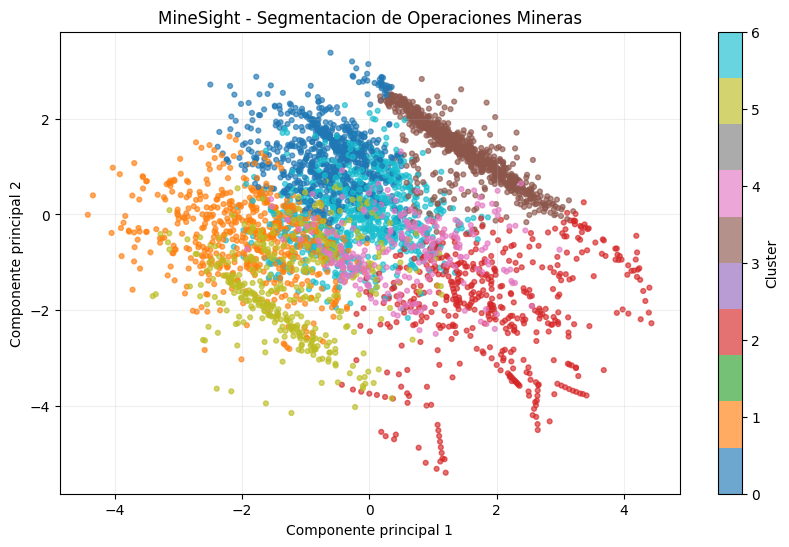

Varianza explicada por PCA: 58.89%


In [8]:

# MINESIGHT - PASO 10: VISUALIZACION DE CLUSTERS

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import pandas as pd

# Reducir las 7 variables a 2 dimensiones
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

# Preparar los datos
visualizacion = pd.DataFrame({
    "PCA 1": X_pca[:, 0],
    "PCA 2": X_pca[:, 1],
    "Cluster": clusters
})

# Crear gráfico
plt.figure(figsize=(10, 6))

grafico = plt.scatter(
    visualizacion["PCA 1"],
    visualizacion["PCA 2"],
    c=visualizacion["Cluster"],
    cmap="tab10",
    s=12,
    alpha=0.65
)

plt.colorbar(grafico, label="Cluster")
plt.title("MineSight - Segmentacion de Operaciones Mineras")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(alpha=0.2)
plt.show()

# Varianza explicada
varianza = pca.explained_variance_ratio_.sum() * 100

print(f"Varianza explicada por PCA: {varianza:.2f}%")


In [9]:

# MINESIGHT - PASO 11: EXPORTAR MODELO

import joblib
import os

# Crear carpeta para los modelos
os.makedirs("/kaggle/working/modelos", exist_ok=True)

# Guardar el modelo K-Means entrenado
joblib.dump(
    modelo_kmeans,
    "/kaggle/working/modelos/minesight_kmeans.pkl"
)

# Guardar el escalador
joblib.dump(
    escalador,
    "/kaggle/working/modelos/minesight_scaler.pkl"
)

# Guardar nombres y orden de variables
joblib.dump(
    variables,
    "/kaggle/working/modelos/minesight_variables.pkl"
)

# Comprobar archivos
print("MODELO MINESIGHT GUARDADO")

for archivo in os.listdir("/kaggle/working/modelos"):
    print(archivo)


MODELO MINESIGHT GUARDADO
minesight_kmeans.pkl
minesight_variables.pkl
minesight_scaler.pkl


In [10]:

import shutil

shutil.make_archive(
    "/kaggle/working/MineSight_Modelo",
    "zip",
    "/kaggle/working/modelos"
)

print("MineSight_Modelo.zip creado correctamente")


MineSight_Modelo.zip creado correctamente


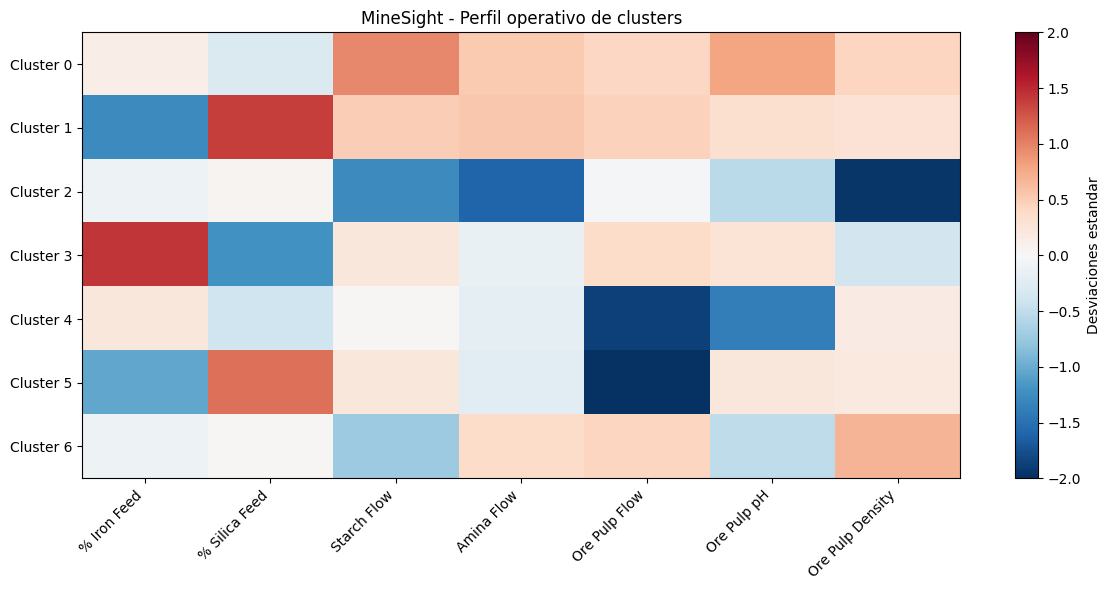

PERFIL PROMEDIO DE LOS CLUSTERS:


,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density
Cluster,,,,,,,
0,56.97,12.71,3775.59,531.62,401.02,10.06,1.71
1,49.75,24.05,3341.13,532.78,401.41,9.89,1.70
2,55.77,15.04,1662.71,354.11,397.27,9.56,1.56
3,63.63,6.41,3088.70,475.21,400.61,9.87,1.66
4,57.50,11.92,2894.73,471.30,382.00,9.24,1.69
5,50.90,22.13,3081.87,469.01,381.00,9.85,1.69
6,55.74,14.78,2184.43,518.94,401.13,9.58,1.72


In [11]:

# MINESIGHT - PASO 12: PERFILAMIENTO DE CLUSTERS

import matplotlib.pyplot as plt
import pandas as pd

# Promedios de cada cluster
perfil = resultado.groupby("Cluster")[variables].mean()

# Comparar con la media general
media = datos_hora[variables].mean()
desviacion = datos_hora[variables].std()

perfil_normalizado = (perfil - media) / desviacion

# Mapa de calor
plt.figure(figsize=(12, 6))

plt.imshow(
    perfil_normalizado,
    cmap="RdBu_r",
    aspect="auto",
    vmin=-2,
    vmax=2
)

plt.colorbar(label="Desviaciones estandar")

plt.xticks(
    range(len(variables)),
    variables,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(perfil.index)),
    [f"Cluster {i}" for i in perfil.index]
)

plt.title("MineSight - Perfil operativo de clusters")
plt.tight_layout()
plt.show()

print("PERFIL PROMEDIO DE LOS CLUSTERS:")
display(perfil.round(2))


CALIDAD PROMEDIO DEL CONCENTRADO POR CLUSTER:


,% Iron Concentrate,% Silica Concentrate
Cluster,,
0,65.27,2.31
1,65.15,2.29
2,64.92,2.42
3,65.16,2.08
4,64.68,2.36
5,64.81,2.27
6,64.99,2.54


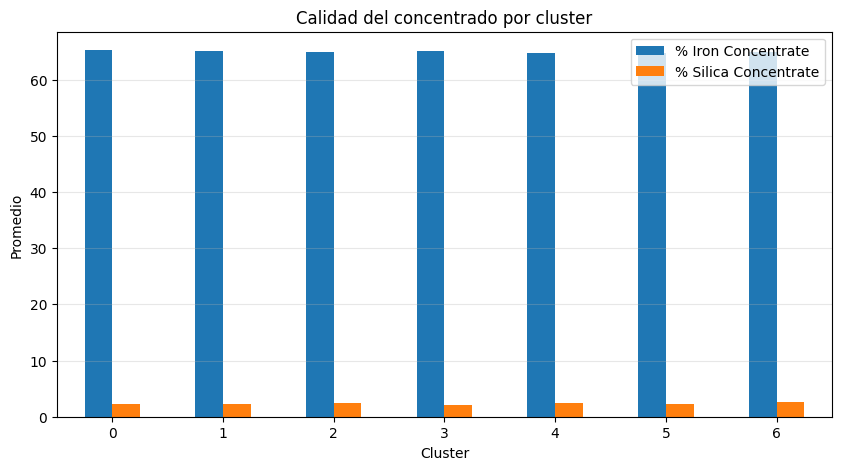

In [12]:
# MINESIGHT - PASO 13: CALIDAD DEL CONCENTRADO POR CLUSTER

# Variables de calidad del concentrado
calidad_vars = ["% Iron Concentrate", "% Silica Concentrate"]

# Crear base con fecha y variables de calidad
calidad_hora = datos.groupby("date")[calidad_vars].mean().dropna()

# Unir con la tabla de clusters por hora
resultado_calidad = resultado.join(calidad_hora, how="inner")

# Promedio de calidad por cluster
calidad_cluster = resultado_calidad.groupby("Cluster")[calidad_vars].mean().round(2)

print("CALIDAD PROMEDIO DEL CONCENTRADO POR CLUSTER:")
display(calidad_cluster)

# Gráfico
calidad_cluster.plot(
    kind="bar",
    figsize=(10,5),
    rot=0,
    title="Calidad del concentrado por cluster"
)

plt.ylabel("Promedio")
plt.grid(axis="y", alpha=0.3)
plt.show()

## Interpretación sectorial de los clusters

El modelo K-Means identificó siete patrones operativos en una planta de flotación de mineral de hierro, diferenciados por las características de alimentación, dosificación de reactivos y condiciones de la pulpa.

- **Cluster 0:** presenta el mayor flujo promedio de almidón (3775.59) y el pH más elevado (10.06), caracterizando operaciones con mayor dosificación de este reactivo.
- **Cluster 1:** registra el menor porcentaje de hierro en la alimentación (49.75 %) y el mayor de sílice (24.05 %).
- **Cluster 2:** presenta los menores flujos promedio de almidón (1662.71) y amina (354.11), así como la menor densidad de pulpa (1.56).
- **Cluster 3:** destaca por el mayor porcentaje de hierro en la alimentación (63.63 %) y el menor porcentaje de sílice (6.41 %).
- **Cluster 4:** registra el menor pH promedio (9.24) y un flujo de pulpa relativamente bajo (382.00).
- **Cluster 5:** presenta el menor flujo promedio de pulpa (381.00) y un contenido elevado de sílice en la alimentación (22.13 %).
- **Cluster 6:** presenta la mayor densidad promedio de pulpa (1.72) y constituye el grupo más frecuente, con 904 observaciones horarias.

### Relación con la calidad del concentrado

Aunque los clusters presentan diferencias operativas, la concentración promedio de hierro en el producto final varía entre 64.68 % y 65.27 %, mientras que la sílice oscila entre 2.08 % y 2.54 %.

Los promedios son cercanos en este historial. La unión por marca horaria es descriptiva. Para interpretar cambios en planta habría que contrastar la alimentación, el desfase entre proceso y laboratorio y las condiciones de operación.

### Interpretación general

MineSight permite identificar y comparar patrones históricos de funcionamiento de una planta minera. Sus resultados pueden apoyar el análisis de condiciones operativas y la identificación de diferencias en la utilización de reactivos.

No obstante, los clusters no representan directamente niveles de eficiencia, riesgo o calidad. Para establecer esas relaciones se requieren análisis adicionales y validación con especialistas del sector minero.
### Caso de uso documentado

Con las siete medias históricas precargadas, la prueba manual documentada en el Writeup devuelve el clúster 6 con distancia 1,2457 al centroide. El perfil histórico de este grupo tiene la mayor densidad media (1,72 en la escala publicada) y reúne 904 horas. La asignación resume la similitud conjunta de las siete variables. La distancia se expresa en el espacio estandarizado.


COMPARACION OPERATIVA POR CLUSTER:


,Starch Flow,Amina Flow,Ore Pulp Flow,% Iron Concentrate,% Silica Concentrate,Almidon / Flujo Pulpa,Amina / Flujo Pulpa
Cluster,,,,,,,
0,3775.595,531.617,401.020,65.266,2.307,9.415,1.326
1,3341.128,532.780,401.412,65.154,2.292,8.323,1.327
2,1662.711,354.114,397.273,64.915,2.421,4.185,0.891
3,3088.702,475.212,400.614,65.161,2.083,7.710,1.186
4,2894.726,471.302,382.001,64.684,2.362,7.578,1.234
5,3081.870,469.013,380.995,64.806,2.271,8.089,1.231
6,2184.426,518.941,401.132,64.988,2.544,5.446,1.294


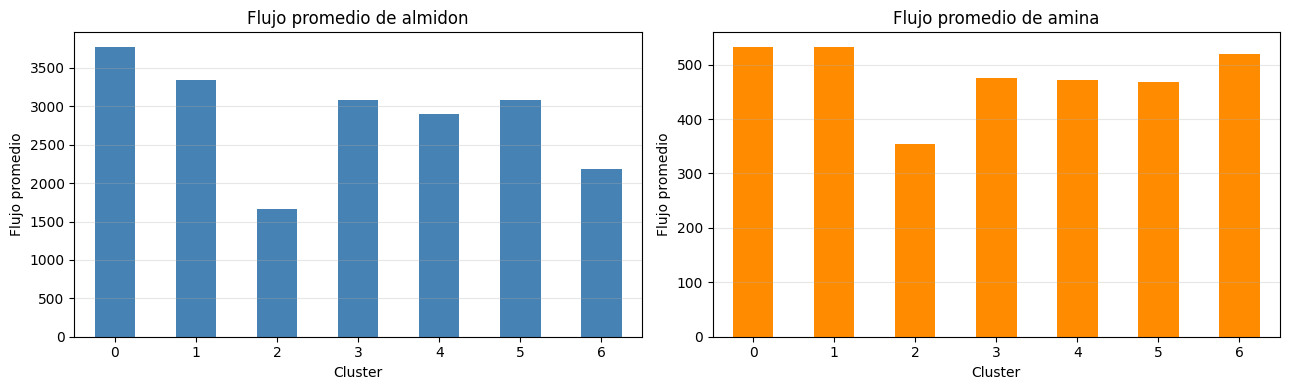

In [13]:

# MINESIGHT - PASO 14
# ANALISIS COMPARATIVO DE REACTIVOS

import pandas as pd
import matplotlib.pyplot as plt

# Calcular promedios por cluster
analisis = resultado_calidad.groupby("Cluster").agg({
    "Starch Flow": "mean",
    "Amina Flow": "mean",
    "Ore Pulp Flow": "mean",
    "% Iron Concentrate": "mean",
    "% Silica Concentrate": "mean"
})

# Indicadores relativos al flujo de pulpa
# No representan consumo especifico por tonelada
analisis["Almidon / Flujo Pulpa"] = (
    analisis["Starch Flow"] / analisis["Ore Pulp Flow"]
)

analisis["Amina / Flujo Pulpa"] = (
    analisis["Amina Flow"] / analisis["Ore Pulp Flow"]
)

print("COMPARACION OPERATIVA POR CLUSTER:")
display(analisis.round(3))

# Graficos independientes
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

analisis["Starch Flow"].plot(
    kind="bar",
    ax=axes[0],
    title="Flujo promedio de almidon",
    color="steelblue"
)

analisis["Amina Flow"].plot(
    kind="bar",
    ax=axes[1],
    title="Flujo promedio de amina",
    color="darkorange"
)

for ax in axes:
    ax.set_xlabel("Cluster")
    ax.set_ylabel("Flujo promedio")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


## Validación cronológica exploratoria

Se replica el pipeline con el [script de GitHub](https://github.com/Marco404-Dev/MineSight/blob/main/docs/validation/temporal.py) como referencia. Se ajustan StandardScaler y K-Means únicamente con horas anteriores al 1 de julio de 2017. Las horas posteriores se transforman con ese escalador y se asignan a los centroides congelados. El umbral descriptivo es el percentil 95 de la distancia mínima observada en ajuste. Esta réplica queda en memoria. Los identificadores de sus clústeres pertenecen a este ajuste y los PKL de producción se conservan.


Percentil 95 de distancia en ajuste: 2.7296


,Horas,Silhouette,Distancia mediana,Horas sobre P95 (%)
Periodo,,,,
Ajuste,2393,0.2314,1.4532,5.01
Evaluación temporal,1704,0.2041,2.8267,52.17


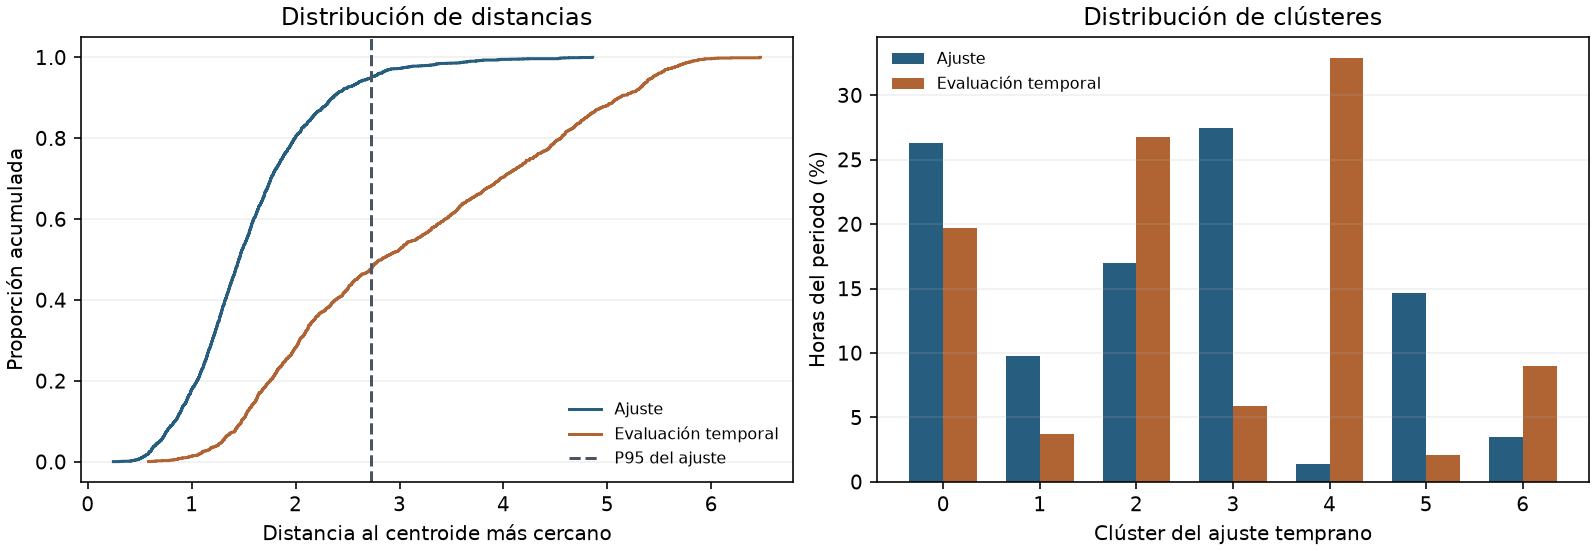

In [14]:
import numpy as np

corte = pd.Timestamp("2017-07-01")
horas_ordenadas = datos_hora.sort_index()
ajuste = horas_ordenadas.loc[horas_ordenadas.index < corte]
evaluacion = horas_ordenadas.loc[horas_ordenadas.index >= corte]

escalador_temporal = StandardScaler()
Z_ajuste = escalador_temporal.fit_transform(ajuste)
Z_evaluacion = escalador_temporal.transform(evaluacion)
modelo_temporal = KMeans(n_clusters=7, random_state=42, n_init=10)
etiquetas_ajuste = modelo_temporal.fit_predict(Z_ajuste)
etiquetas_evaluacion = modelo_temporal.predict(Z_evaluacion)
dist_ajuste = modelo_temporal.transform(Z_ajuste).min(axis=1)
dist_evaluacion = modelo_temporal.transform(Z_evaluacion).min(axis=1)
umbral = np.percentile(dist_ajuste, 95)

periodos = (
    ("Ajuste", Z_ajuste, etiquetas_ajuste, dist_ajuste),
    ("Evaluación temporal", Z_evaluacion, etiquetas_evaluacion, dist_evaluacion),
)
resumen_temporal = pd.DataFrame([
    {
        "Periodo": nombre,
        "Horas": len(z),
        "Silhouette": silhouette_score(z, etiquetas),
        "Distancia mediana": np.median(distancias),
        "Horas sobre P95 (%)": 100 * np.mean(distancias > umbral),
    }
    for nombre, z, etiquetas, distancias in periodos
]).set_index("Periodo")
print(f"Percentil 95 de distancia en ajuste: {umbral:.4f}")
display(resumen_temporal.round({"Silhouette": 4, "Distancia mediana": 4, "Horas sobre P95 (%)": 2}))

fig, (ax_dist, ax_grupos) = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
colores = ["#275D7F", "#B06433"]
grupos = np.arange(7)
for i, (nombre, z, etiquetas, distancias) in enumerate(periodos):
    ordenadas = np.sort(distancias)
    ax_dist.step(ordenadas, np.arange(1, len(z) + 1) / len(z), where="post",
                 color=colores[i], label=nombre)
    participacion = 100 * np.bincount(etiquetas, minlength=7) / len(z)
    ax_grupos.bar(grupos + (i - 0.5) * 0.35, participacion, width=0.35,
                  color=colores[i], label=nombre)
ax_dist.axvline(umbral, color="#4B5563", linestyle="--", label="P95 del ajuste")
ax_dist.set(title="Distribución de distancias", xlabel="Distancia al centroide más cercano",
            ylabel="Proporción acumulada")
ax_grupos.set(title="Distribución de clústeres", xlabel="Clúster del ajuste temprano",
              ylabel="Horas del periodo (%)", xticks=grupos)
for eje in (ax_dist, ax_grupos):
    eje.grid(axis="y", alpha=0.2)
    eje.legend(frameon=False, fontsize=8)
plt.show()


En la evaluación posterior, la mediana pasó de **1,4532** a **2,8267** y el porcentaje sobre el P95 del ajuste pasó de **5,01 %** a **52,17 %**. El silhouette bajó de **0,2314** a **0,2041**. Las distancias euclidianas se expresan en el espacio estandarizado con parámetros del periodo temprano. El desplazamiento de sus distribuciones muestra menor similitud con los perfiles entrenados en ese periodo. El umbral de 2,7296 es una referencia descriptiva. Para usar distancias como señal operativa se requieren campañas identificadas, controles de calidad de mediciones y validación con especialistas. El ejercicio usa un único corte de una planta y carece de etiquetas de falla o riesgo.


## Potencial de impacto

Los indicadores se derivan de las tablas guardadas de distribución, calidad y reactivos. Las diferencias relativas se calcularon sobre los valores de flujo mostrados, con el clúster 0 como base.

| Indicador | Cálculo sobre el historial | Lectura para planta |
|---|---|---|
| Frecuencia del clúster 6 | 100 × 904 / 4 097 = **22,06 %** de las horas analizadas | Referencia para comparar la mezcla de condiciones de un turno o lote posterior. |
| Brecha de caudal de reactivos, clúster 2 frente al 0 | 100 × (media del clúster 0 − media del clúster 2) / media del clúster 0. Almidón: 3 775,59 frente a 1 662,71 (**55,96 %**). Amina: 531,62 frente a 354,11 (**33,39 %**). | Señala qué grupos vale la pena revisar junto con la alimentación y las propiedades de la pulpa. |
| Caudal de reactivo relativo al de pulpa | Media horaria del caudal de reactivo del grupo / media horaria del caudal de pulpa del grupo, sobre las horas con datos de calidad. Clúster 0 → 2: almidón **9,415 → 4,185** y amina **1,326 → 0,891**. | Sirve para comparar flujos registrados entre grupos. La pulpa incluye agua y el caudal de solución no equivale a masa de reactivo activo. |
| Ley e impureza del concentrado | Media aritmética de los promedios horarios unidos al grupo. Clúster 0 → 2: Fe **65,27 % → 64,92 %** (−0,35 puntos porcentuales) y sílice **2,31 % → 2,42 %** (+0,11 puntos porcentuales), a partir de las medias redondeadas de la tabla de calidad. | Contextualiza los contrastes de caudal. Son asociaciones históricas entre condiciones diferentes. |

En un piloto, el metalurgista podría medir el tiempo de revisión con y sin MineSight sobre lotes comparables. La reducción relativa se calcularía como 100 × (mediana de minutos con el flujo actual − mediana de minutos con MineSight) / mediana de minutos con el flujo actual. También se podría contrastar la distribución de grupos por campaña. El estudio carece de mediciones del piloto, costos y balance metalúrgico. Para medir consumo específico se necesitan kg de reactivo activo y toneladas secas tratadas del mismo periodo. Para medir recuperación de hierro se requieren flujos másicos secos y leyes de alimentación y concentrado.


## 7. Conclusiones

- K-Means obtuvo silhouette 0,2262, Davies–Bouldin 1,3357 y Calinski–Harabasz 917,3293. MiniBatch K-Means obtuvo 0,1972, 1,4672 y 865,4150, respectivamente, sobre las mismas horas. k=7 supera a k=4 por 0,0012 de silhouette redondeado.
- El ARI medio fue 0,9959 en cuatro comparaciones contra semilla 0. El resultado respalda la estabilidad de la inicialización en este conjunto.
- Los siete perfiles permiten comparar condiciones históricas de alimentación, reactivos y pulpa. Las brechas de caudal sirven para seleccionar casos que ameritan revisión metalúrgica.

## 8. Limitaciones e implementación industrial

La separación es limitada (silhouette 0,2262). El modelo cubre una planta y un periodo de 2017. La agregación por hora oculta transitorios y la estabilidad observada frente a semillas sobre el mismo historial deja abierta la estabilidad ante cambios de campaña, mineral y calibración. La asignación al centroide más cercano es exploratoria y carece de validación como diagnóstico, pronóstico de calidad o regla de dosificación.

Para un piloto en modo de observación, el metalurgista y el equipo de instrumentación deberían verificar el mapeo de etiquetas del historiador, las unidades, el sentido físico de los rangos, la cobertura horaria y el desfase con laboratorio. Conviene contrastar perfiles y distancias en ventanas temporales posteriores y revisar casos con especialistas antes de incorporar umbrales de alerta. El producto puede apoyar revisiones de turno e investigaciones de variabilidad por campaña. Una integración con el historiador requeriría un entorno autorizado para los datos operativos.

## 9. Aplicación desarrollada

Next.js en Vercel envía la entrada manual o por CSV a FastAPI en Render. La API comprueba los PKL originales por SHA-256, valida las variables y aplica el escalador y K-Means en el orden de entrenamiento. La interfaz muestra la asignación, los perfiles, la distribución del lote y el PCA cuando hay variación suficiente. Permite exportar operaciones, resumen y reporte.

Para la demo, usa las medias precargadas en **Predicción manual** o valida un archivo con las siete cabeceras en **Análisis CSV**.

## 10. Contribuciones del equipo

- **Ancco Quispe Marco Antonio:** Desarrollo y entrenamiento del modelo K-Means, evaluación de métricas y análisis de resultados.
- **Ancco Quispe Juan:** Recolección, limpieza, transformación y preparación del dataset minero.
- **Mogollon Josue:** Desarrollo de la aplicación web MineSight e integración del modelo de Machine Learning.
- **Berrocal Juan:** Análisis exploratorio de datos, visualización de clusters e interpretación de patrones operativos.
- **Quispe Dylan:** Documentación técnica, pruebas funcionales, elaboración de conclusiones y preparación de la exposición.

[Notebook en Kaggle](https://www.kaggle.com/code/marcoanccoquispe/minesight-clustering-y-segmentaci-n-minera) · [Código en GitHub](https://github.com/Marco404-Dev/MineSight) · [Demo en Vercel](https://minesight-vert.vercel.app/) · [Writeup](https://github.com/Marco404-Dev/MineSight/blob/main/docs/MineSight_WriteUp.pdf)
